# Retail Sales Intelligence: EDA & Data Visualization
### CodeAlpha Data Analytics — Task 2 and Task 3

**Goal:** Explore a Kaggle Superstore dataset, validate data quality, calculate business KPIs, discover sales/profit patterns, and create decision-support visualizations.

**Dataset:** [Superstore Dataset Final — Kaggle](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)

> In Google Colab, run the cells from top to bottom. Upload the CSV when prompted. The notebook does not assume a local Windows path.

## 1. Install and import libraries
The main libraries are usually preinstalled in Colab. This cell installs or upgrades the required packages.

In [23]:
!pip -q install pandas numpy matplotlib seaborn

In [24]:
import io
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# OUTPUT_DIR = Path("/content/retail_sales_outputs")
# FIGURE_DIR = OUTPUT_DIR / "figures"
# TABLE_DIR = OUTPUT_DIR / "tables"
# FIGURE_DIR.mkdir(parents=True, exist_ok=True)
# TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Environment ready.")

Environment ready.


## 2. Upload the Kaggle dataset

1. Download the CSV from the Kaggle dataset page.
2. In Colab, run this cell and choose the downloaded CSV file.
3. The notebook reads the uploaded file directly; no need to paste a Windows path.

Expected columns include `Order ID`, `Order Date`, `Sales`, `Profit`, `Category`, and `Region`.

In [25]:
# uploaded = files.upload()
# if not uploaded:
#     raise ValueError("No file uploaded. Please upload the Superstore CSV.")

# csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
# if not csv_names:
#     raise ValueError("Please upload a CSV file.")

# # Use the first uploaded CSV. If multiple CSVs were selected, choose the correct one here.
# DATA_FILE_NAME = csv_names[0]
# raw_df = pd.read_csv(io.BytesIO(uploaded[DATA_FILE_NAME]), encoding="latin-1")
# print(f"Loaded: {DATA_FILE_NAME}")
# print(f"Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
# display(raw_df.head())

#Load the dataset
raw_df = pd.read_csv("/content/Sample - Superstore.csv", encoding="latin-1")
print(f"Loaded: Superstore.csv")
print(f"Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())

Loaded: Superstore.csv
Shape: 9,994 rows × 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


## 3. Ask meaningful business questions
We will investigate:
- What are total sales, profit, order count and profit margin?
- Which categories, sub-categories, regions and customer segments perform best?
- How do sales and profit change over time?
- Are higher discounts associated with lower profit?
- What missing values, duplicates or invalid records need attention?

## 4. Inspect structure and data quality

In [26]:
print("Dataset information:")
raw_df.info()

print("\nFirst five rows:")
display(raw_df.head())

print("\nDescriptive statistics:")
display(raw_df.describe(include="all").T)

quality_before = pd.DataFrame({
    "data_type": raw_df.dtypes.astype(str),
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2),
    "unique_values": raw_df.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)

display(quality_before)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,"9,994.00",NaN,NaN,NaN,"4,997.50","2,885.16",1.00,"2,499.25","4,997.50","7,495.75","9,994.00"
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,data_type,missing_count,missing_percent,unique_values
Row ID,int64,0,0.00,9994
Order ID,object,0,0.00,5009
Order Date,object,0,0.00,1237
Ship Date,object,0,0.00,1334
Ship Mode,object,0,0.00,4
Customer ID,object,0,0.00,793
Customer Name,object,0,0.00,793
Segment,object,0,0.00,3
Country,object,0,0.00,1
City,object,0,0.00,531


## 5. Clean and prepare the data
The notebook standardizes column names, parses dates, converts numeric columns, removes exact duplicate rows, and excludes records missing essential analysis fields. Repeated Order IDs are retained because one order may contain multiple product lines.

In [27]:
df = raw_df.copy()
df.columns = [
    re.sub(r"_+", "_", re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower())).strip("_")
    for c in df.columns
]

required = {"order_id", "order_date", "sales", "profit", "category", "region"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(
        f"Required columns not found: {sorted(missing_required)}. "
        f"Available columns: {list(df.columns)}"
    )

for col in ["order_date", "ship_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

for col in ["sales", "profit", "quantity", "discount"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

before_duplicates = len(df)
df = df.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {before_duplicates - len(df):,}")

essential = ["order_id", "order_date", "sales", "profit", "category", "region"]
before_missing = len(df)
df = df.dropna(subset=essential).copy()
print(f"Rows removed due to missing essential fields: {before_missing - len(df):,}")

df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.to_period("M").astype(str)
df["profit_margin_pct"] = np.where(df["sales"] != 0, df["profit"] / df["sales"] * 100, np.nan)

if "ship_date" in df.columns:
    df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df.loc[df["shipping_days"] < 0, "shipping_days"] = np.nan

if "discount" in df.columns:
    df["discount_band"] = pd.cut(
        df["discount"],
        bins=[-0.001, 0, 0.10, 0.20, 0.30, 1.0],
        labels=["No discount", "0–10%", "10–20%", "20–30%", "30%+"],
        include_lowest=True
    )

print(f"Cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Exact duplicate rows removed: 0
Rows removed due to missing essential fields: 0
Cleaned dataset: 9,994 rows × 26 columns


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,order_year,order_month,profit_margin_pct,shipping_days,discount_band
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2016,2016-11,16.00,3.00,No discount
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2016,2016-11,30.00,3.00,No discount
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,2016,2016-06,47.00,4.00,No discount
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03,2015,2015-10,-40.00,7.00,30%+
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52,2015,2015-10,11.25,7.00,10–20%


## 6. Calculate business KPIs

In [30]:
kpis = {
    "Transaction line items": len(df),
    "Unique orders": df["order_id"].nunique(),
    "Unique customers": df["customer_id"].nunique() if "customer_id" in df.columns else np.nan,
    "Total sales": df["sales"].sum(),
    "Total profit": df["profit"].sum(),
    "Overall profit margin (%)": (df["profit"].sum() / df["sales"].sum() * 100) if df["sales"].sum() else np.nan,
    "Average discount": df["discount"].mean() if "discount" in df.columns else np.nan,
    "Average quantity": df["quantity"].mean() if "quantity" in df.columns else np.nan
}
kpi_df = pd.DataFrame({"KPI": list(kpis.keys()), "Value": list(kpis.values())})
display(kpi_df)
# kpi_df.to_csv(TABLE_DIR / "business_kpis.csv", index=False)

,KPI,Value
0,Transaction line items,"9,994.00"
1,Unique orders,"5,009.00"
2,Unique customers,793.00
3,Total sales,"2,297,200.86"
4,Total profit,"286,397.02"
5,Overall profit margin (%),12.47
6,Average discount,0.16
7,Average quantity,3.79


## 7. Analyze category, region, segment and sub-category performance

In [32]:
def grouped_summary(data, group_col):
    return (data.groupby(group_col, dropna=False)
            .agg(sales=("sales", "sum"),
                 profit=("profit", "sum"),
                 average_discount=("discount", "mean") if "discount" in data.columns else ("sales", "size"),
                 line_items=("order_id", "size"))
            .sort_values("sales", ascending=False)
            .reset_index())

for col in ["category", "region", "segment", "sub_category"]:
    if col in df.columns:
        summary = grouped_summary(df, col)
        print(f"\nPerformance by {col}:")
        display(summary)
        # summary.to_csv(TABLE_DIR / f"performance_by_{col}.csv", index=False)


Performance by category:


,category,sales,profit,average_discount,line_items
0,Technology,"836,154.03","145,454.95",0.13,1847
1,Furniture,"741,999.80","18,451.27",0.17,2121
2,Office Supplies,"719,047.03","122,490.80",0.16,6026



Performance by region:


,region,sales,profit,average_discount,line_items
0,West,"725,457.82","108,418.45",0.11,3203
1,East,"678,781.24","91,522.78",0.15,2848
2,Central,"501,239.89","39,706.36",0.24,2323
3,South,"391,721.91","46,749.43",0.15,1620



Performance by segment:


,segment,sales,profit,average_discount,line_items
0,Consumer,"1,161,401.34","134,119.21",0.16,5191
1,Corporate,"706,146.37","91,979.13",0.16,3020
2,Home Office,"429,653.15","60,298.68",0.15,1783



Performance by sub_category:


,sub_category,sales,profit,average_discount,line_items
0,Phones,"330,007.05","44,515.73",0.15,889
1,Chairs,"328,449.10","26,590.17",0.17,617
2,Storage,"223,843.61","21,278.83",0.07,846
3,Tables,"206,965.53","-17,725.48",0.26,319
4,Binders,"203,412.73","30,221.76",0.37,1523
5,Machines,"189,238.63","3,384.76",0.31,115
6,Accessories,"167,380.32","41,936.64",0.08,775
7,Copiers,"149,528.03","55,617.82",0.16,68
8,Bookcases,"114,880.00","-3,472.56",0.21,228
9,Appliances,"107,532.16","18,138.01",0.17,466


## 8. Monthly sales and profit trends

,order_month,sales,profit,unique_orders
0,2014-01,"14,236.90","2,450.19",32
1,2014-02,"4,519.89",862.31,28
2,2014-03,"55,691.01",498.73,71
3,2014-04,"28,295.35","3,488.84",66
4,2014-05,"23,648.29","2,738.71",69


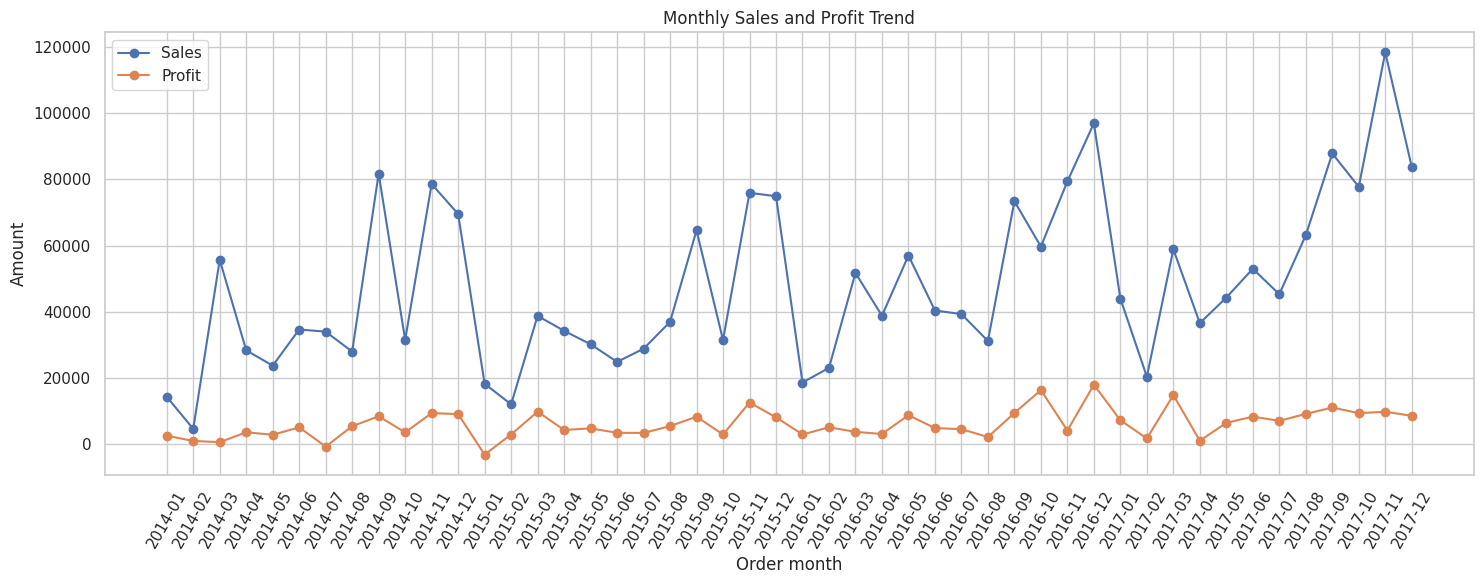

In [34]:
monthly = (df.groupby("order_month", as_index=False)
           .agg(sales=("sales", "sum"),
                profit=("profit", "sum"),
                unique_orders=("order_id", "nunique")))
display(monthly.head())

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(monthly["order_month"], monthly["sales"], marker="o", label="Sales")
ax.plot(monthly["order_month"], monthly["profit"], marker="o", label="Profit")
ax.set_title("Monthly Sales and Profit Trend")
ax.set_xlabel("Order month")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.tight_layout()
# plt.savefig(FIGURE_DIR / "monthly_sales_profit.png", dpi=180, bbox_inches="tight")
plt.show()
# monthly.to_csv(TABLE_DIR / "monthly_performance.csv", index=False)

## 9. Visualize category and regional performance

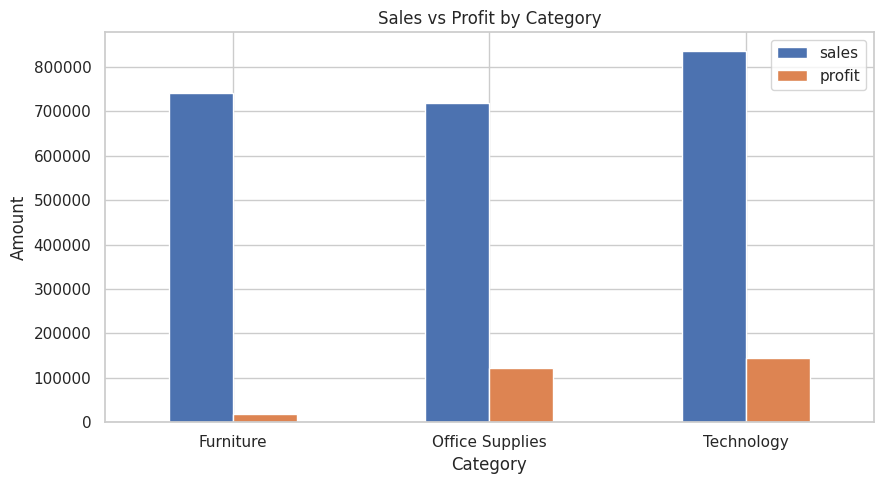

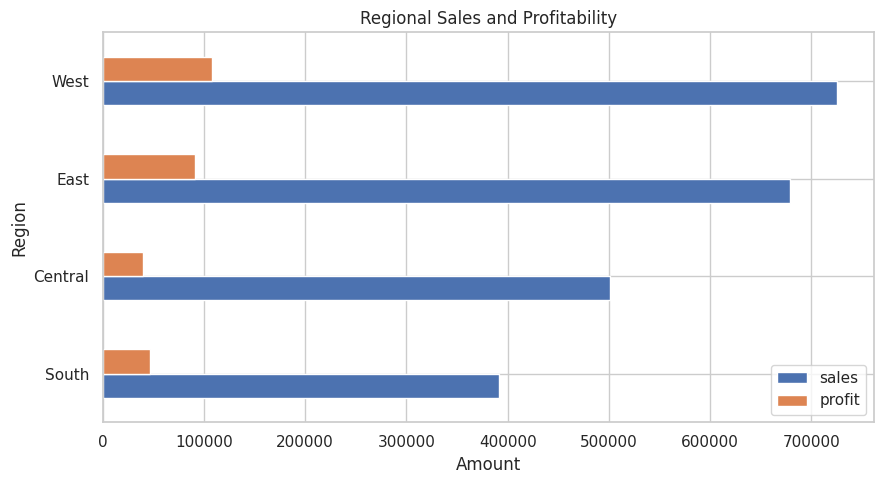

In [35]:
category_summary = df.groupby("category", as_index=False)[["sales", "profit"]].sum()
fig, ax = plt.subplots(figsize=(9, 5))
category_summary.set_index("category")[["sales", "profit"]].plot(kind="bar", ax=ax)
ax.set_title("Sales vs Profit by Category")
ax.set_xlabel("Category")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
# plt.savefig(FIGURE_DIR / "category_sales_profit.png", dpi=180, bbox_inches="tight")
plt.show()

region_summary = df.groupby("region", as_index=False)[["sales", "profit"]].sum().sort_values("sales")
fig, ax = plt.subplots(figsize=(9, 5))
region_summary.set_index("region")[["sales", "profit"]].plot(kind="barh", ax=ax)
ax.set_title("Regional Sales and Profitability")
ax.set_xlabel("Amount")
ax.set_ylabel("Region")
plt.tight_layout()
# plt.savefig(FIGURE_DIR / "regional_performance.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Investigate sub-category profit and discount patterns

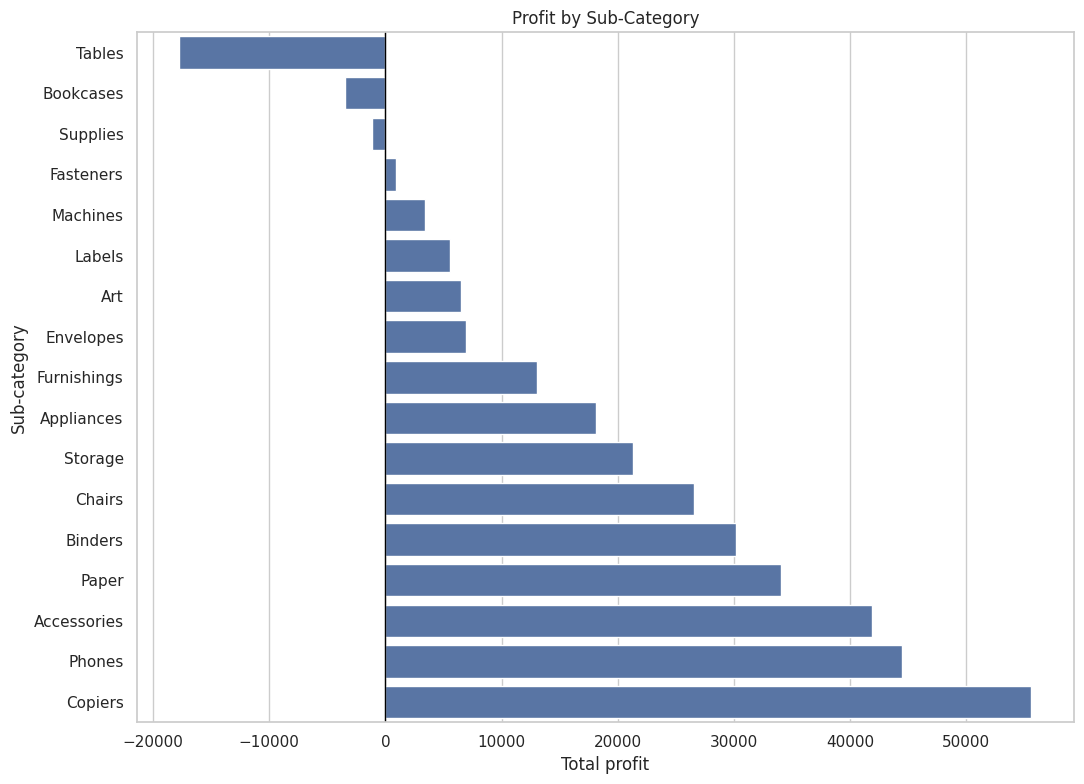

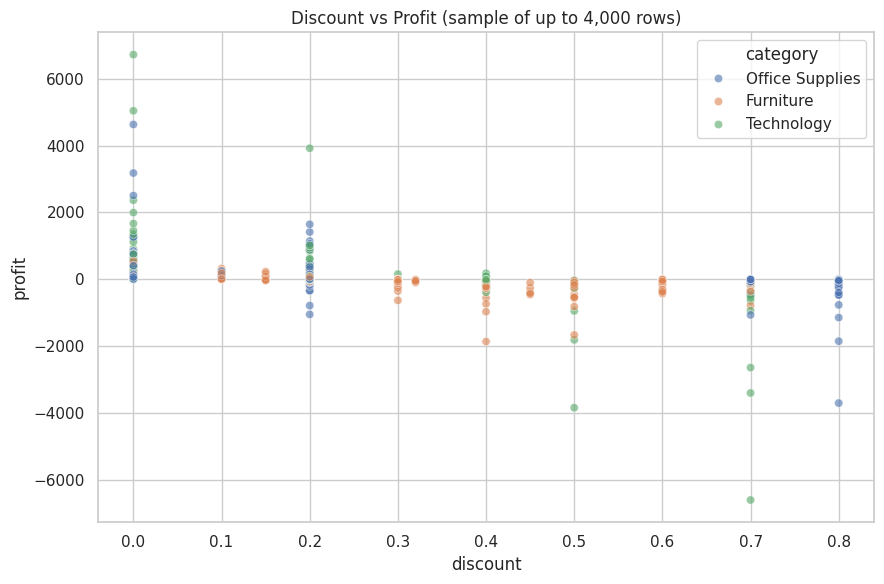

In [36]:
if "sub_category" in df.columns:
    sub = df.groupby("sub_category", as_index=False)["profit"].sum().sort_values("profit")
    fig, ax = plt.subplots(figsize=(11, 8))
    sns.barplot(data=sub, x="profit", y="sub_category", ax=ax)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title("Profit by Sub-Category")
    ax.set_xlabel("Total profit")
    ax.set_ylabel("Sub-category")
    plt.tight_layout()
    # plt.savefig(FIGURE_DIR / "subcategory_profit.png", dpi=180, bbox_inches="tight")
    plt.show()

if {"discount", "profit"}.issubset(df.columns):
    sample = df.sample(min(len(df), 4000), random_state=42)
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.scatterplot(data=sample, x="discount", y="profit", hue="category", alpha=0.6, ax=ax)
    ax.set_title("Discount vs Profit (sample of up to 4,000 rows)")
    plt.tight_layout()
    # plt.savefig(FIGURE_DIR / "discount_vs_profit.png", dpi=180, bbox_inches="tight")
    plt.show()

## 11. Test simple hypotheses and validate assumptions
These are exploratory comparisons, not causal tests. Interpret group averages alongside sample sizes and business context.

In [37]:
if "discount_band" in df.columns:
    discount_analysis = (df.groupby("discount_band", observed=True)
                         .agg(transaction_lines=("order_id", "size"),
                              average_sales=("sales", "mean"),
                              average_profit=("profit", "mean"),
                              total_profit=("profit", "sum"))
                         .reset_index())
    display(discount_analysis)
    # discount_analysis.to_csv(TABLE_DIR / "discount_band_analysis.csv", index=False)

print("Numeric correlation matrix (association only):")
display(df.select_dtypes(include=np.number).corr(numeric_only=True).round(2))

,discount_band,transaction_lines,average_sales,average_profit,total_profit
0,No discount,4798,226.74,66.90,"320,987.60"
1,0–10%,94,578.40,96.06,"9,029.18"
2,10–20%,3709,213.58,24.74,"91,756.30"
3,20–30%,227,454.74,-45.68,"-10,369.28"
4,30%+,1166,222.59,-107.21,"-125,006.78"


Numeric correlation matrix (association only):


,row_id,postal_code,sales,quantity,discount,profit,order_year,profit_margin_pct,shipping_days
row_id,1.00,0.01,-0.00,-0.00,0.01,0.01,0.02,-0.02,-0.00
postal_code,0.01,1.00,-0.02,0.01,0.06,-0.03,0.00,-0.06,-0.01
sales,-0.00,-0.02,1.00,0.20,-0.03,0.48,-0.01,0.00,-0.01
quantity,-0.00,0.01,0.20,1.00,0.01,0.07,-0.01,-0.01,0.02
discount,0.01,0.06,-0.03,0.01,1.00,-0.22,-0.00,-0.86,0.00
profit,0.01,-0.03,0.48,0.07,-0.22,1.00,0.00,0.22,-0.00
order_year,0.02,0.00,-0.01,-0.01,-0.00,0.00,1.00,0.00,-0.02
profit_margin_pct,-0.02,-0.06,0.00,-0.01,-0.86,0.22,0.00,1.00,-0.01
shipping_days,-0.00,-0.01,-0.01,0.02,0.00,-0.00,-0.02,-0.01,1.00


## 12. Final data-quality report and export

In [38]:
quality_after = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)

display(quality_after)
# quality_after.to_csv(TABLE_DIR / "data_quality_report.csv")
# df.to_csv(OUTPUT_DIR / "cleaned_superstore_data.csv", index=False)

print("Saved output files:")
# for p in sorted(OUTPUT_DIR.rglob("*")):
#     if p.is_file():
#         print(p)

,data_type,missing_count,missing_percent,unique_values
row_id,int64,0,0.00,9994
order_id,object,0,0.00,5009
order_date,datetime64[ns],0,0.00,1237
ship_date,datetime64[ns],0,0.00,1334
ship_mode,object,0,0.00,4
customer_id,object,0,0.00,793
customer_name,object,0,0.00,793
segment,object,0,0.00,3
country,object,0,0.00,1
city,object,0,0.00,531


Saved output files:


## 13. Conclusion and future scope

Use your generated tables and charts to write evidence-based findings, for example:
- Which category and region generated the highest sales?
- Which sub-categories generated losses?
- How did monthly sales and profit change?
- What patterns appear between discount levels and profit?

**Do not write conclusions until you inspect your actual outputs.** A discount/profit relationship is an association, not proof of causation.

**Future scope:** interactive Power BI/Tableau dashboard, SQL analysis, customer RFM segmentation, cohort analysis, time-series forecasting with chronological validation, and automated data-quality tests.

**Dataset attribution:** Vivek Chowdhury, *Superstore Dataset Final*, Kaggle. Review the dataset page's license and terms before redistribution or commercial use.